N_i = -4.605170
delta_i = 1.000000e-04
f_i = 1.000000
delta_N,i = 1.000000e-04
theta_i = -9.999000e-05
g_i = 1.000000e+04


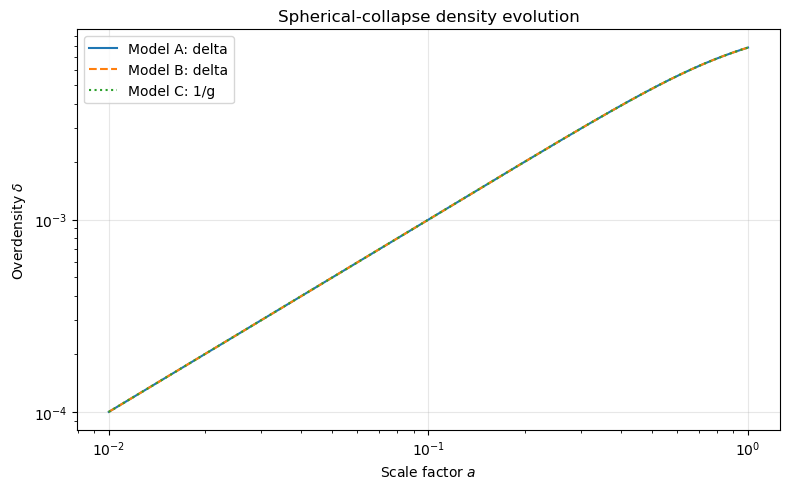

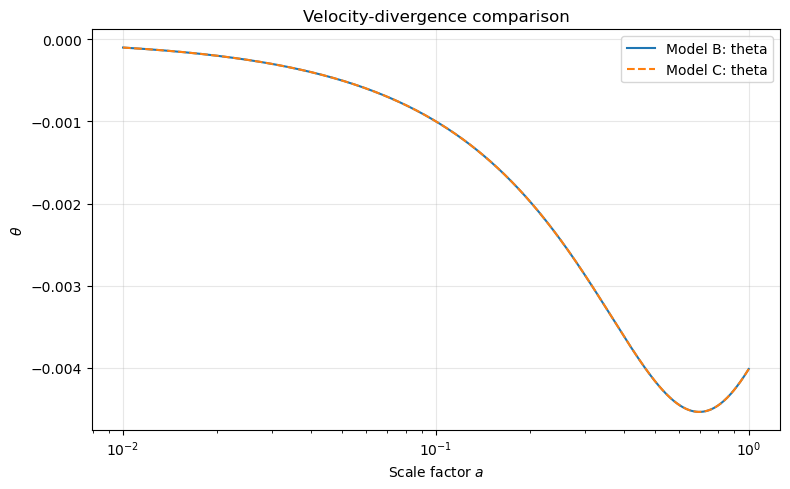

Model A: delta(a_i) = 1.000000e-04, delta(a_f) = 7.838410e-03
Model B: delta(a_i) = 1.000000e-04, delta(a_f) = 7.838410e-03
Model C: delta(a_i) = 1.000000e-04, delta(a_f) = 7.838408e-03


In [1]:
import numpy as np
import matplotlib.pyplot as plt

from spherical_collapse import SphericalCollapse
from cosmology import FLRW

#EDS OM_M=1;OM_DE=0
#FLAT ACDM OM_M=0.3;OM_DE=0.7

#Flat ACDM H_N/N=-3OM_M/2

#EdS, AH=1/2


cosmology = FLRW(
    h=0.67,
    Omega_m=0.3,
    Omega_lambda=0.7,
    Omega_r=0.0,
    w0_fld=-1.0,
    wa_fld=0.0,
)

collapse = SphericalCollapse(cosmology)

ai = 0.01
af = 1.0
delta_i = 1e-4

# Replace this with the growth rate from Exercise 1 at a = ai.
f_i = 1.0

theta_i = -f_i * delta_i / (1.0 + delta_i)
g_i = 1.0 / delta_i

print(f"N_i = {np.log(ai):.6f}")
print(f"delta_i = {delta_i:.6e}")
print(f"f_i = {f_i:.6f}")
print(f"delta_N,i = {f_i * delta_i:.6e}")
print(f"theta_i = {theta_i:.6e}")
print(f"g_i = {g_i:.6e}")

result = collapse.integrate(
    ai=ai,
    af=af,
    delta_i=delta_i,
    f_i=f_i,
    n_points=1000,
)

a = result["a"]

sol_A = result["Model_A"]  # y = [delta, delta_N]
sol_B = result["Model_B"]  # y = [delta, theta]
sol_C = result["Model_C"]  # y = [g, theta]

delta_A = sol_A.y[0]
delta_B = sol_B.y[0]
g_C = sol_C.y[0]

# Since Model C evolves g = 1/delta, recover its overdensity.
delta_C = 1.0 / g_C

plt.figure(figsize=(8, 5))
plt.plot(a, delta_A, label="Model A: delta")
plt.plot(a, delta_B, "--", label="Model B: delta")
plt.plot(a, delta_C, ":", label="Model C: 1/g")
plt.xscale("log")
plt.yscale("log")
plt.xlabel(r"Scale factor $a$")
plt.ylabel(r"Overdensity $\delta$")
plt.title("Spherical-collapse density evolution")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

theta_B = sol_B.y[1]
theta_C = sol_C.y[1]

plt.figure(figsize=(8, 5))
plt.plot(a, theta_B, label="Model B: theta")
plt.plot(a, theta_C, "--", label="Model C: theta")
plt.xscale("log")
plt.xlabel(r"Scale factor $a$")
plt.ylabel(r"$\theta$")
plt.title("Velocity-divergence comparison")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

for name, delta_model in [
    ("Model A", delta_A),
    ("Model B", delta_B),
    ("Model C", delta_C),
]:
    print(
        f"{name}: delta(a_i) = {delta_model[0]:.6e}, "
        f"delta(a_f) = {delta_model[-1]:.6e}"
    )



In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp

from cosmology import FLRW
from spherical_collapse import (
    SphericalCollapse,
    CollapseThreshold,
)

cosmology = FLRW(
    h=0.67,
    Omega_m=0.3,
    Omega_lambda=0.7,
    Omega_r=0.0,
    w0_fld=-1.0,
    wa_fld=0.0,
)

a_grid = np.geomspace(1e-6, 1.0, 2000)
N_grid = np.log(a_grid)

growth_sol = cosmology.solve_growth(
    N=N_grid,
    y0=[1e-6, 1e-6],
    rtol=1e-10,
    atol=1e-12,
)

if not growth_sol.success:
    raise RuntimeError(growth_sol.message)

def growth_rate(cosmology, growth_sol, ai):
    """
    Calculate f = dln(D)/dln(a) at ai.
    """
    _, f_i = cosmology.get_growth_observables(
        growth_sol,
        N_eval=np.array([np.log(ai)]),
    )

    return float(f_i[0])

models = ["A", "B", "C"]
redshifts = [0, 0.5, 1, 2, 3]

ai = 0.01
delta_stop = 1e4

collapse = SphericalCollapse(
    cosmology=cosmology,
)

results = []

for model in models:
    for z_c in redshifts:

        f_i = growth_rate(cosmology, growth_sol, ai)

        threshold = CollapseThreshold(
            collapse=collapse,
            model=model,
            ai=ai,
            delta_stop=delta_stop,
            f_i=f_i,
            n_points=1000,
            delta_i_min=1e-8,
            delta_i_max=1e-2,
            tol=1e-10,
            max_iter=100,
        )

        delta_i, delta_c = threshold.find(z_c)

        results.append({
            "Model": model,
            "z_c": z_c,
            "a_c": 1.0 / (1.0 + z_c),
            "f_i": f_i,
            "delta_i": delta_i,
            "delta_c": delta_c,
        })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

pivot = results_df.pivot(
    index="z_c",
    columns="Model",
    values="delta_c",
)

print("Linear collapse thresholds:")
print(pivot)

relative_difference = 100.0 * pivot.div(
    pivot["A"],
    axis=0,
).subtract(1.0)

print("\nRelative difference with respect to Model A (%):")
print(relative_difference)

plt.figure(figsize=(8, 5))

for model in models:
    subset = results_df[results_df["Model"] == model]

    plt.plot(
        subset["z_c"],
        subset["delta_c"],
        marker="o",
        label=f"Model {model}",
    )

plt.xlabel(r"Collapse redshift $z_c$")
plt.ylabel(r"Linear collapse threshold $\delta_c$")
plt.title(r"Spherical collapse in flat $\Lambda$CDM")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

Model  z_c      a_c      f_i  delta_i  delta_c
    A  0.0 1.000000 0.999999 0.021895 1.705605
    A  0.5 0.666667 0.999999 0.028632 1.724477
    A  1.0 0.500000 0.999999 0.036547 1.741764
    A  2.0 0.333333 0.999999 0.054105 1.776274
    A  3.0 0.250000 0.999999 0.072955 1.811997
    B  0.0 1.000000 0.999999 0.021895 1.705605
    B  0.5 0.666667 0.999999 0.028632 1.724477
    B  1.0 0.500000 0.999999 0.036547 1.741764
    B  2.0 0.333333 0.999999 0.054105 1.776274
    B  3.0 0.250000 0.999999 0.072955 1.811997
    C  0.0 1.000000 0.999999 0.021895 1.705605
    C  0.5 0.666667 0.999999 0.028632 1.724477
    C  1.0 0.500000 0.999999 0.036547 1.741764
    C  2.0 0.333333 0.999999 0.054105 1.776274
    C  3.0 0.250000 0.999999 0.072955 1.811997
Linear collapse thresholds:
Model         A         B         C
z_c                                
0.0    1.705605  1.705605  1.705605
0.5    1.724477  1.724477  1.724477
1.0    1.741764  1.741764  1.741764
2.0    1.776274  1.776274  1.776274
3.0 

Model  z_c      a_c  f_i  delta_i  delta_c
    A  0.0 1.000000  1.0 0.017072 1.707208
    A  0.5 0.666667  1.0 0.025857 1.723810
    A  1.0 0.500000  1.0 0.034814 1.740707
    A  2.0 0.333333  1.0 0.053262 1.775411
    A  3.0 0.250000  1.0 0.072455 1.811378
    B  0.0 1.000000  1.0 0.017072 1.707208
    B  0.5 0.666667  1.0 0.025857 1.723810
    B  1.0 0.500000  1.0 0.034814 1.740707
    B  2.0 0.333333  1.0 0.053262 1.775411
    B  3.0 0.250000  1.0 0.072455 1.811378
    C  0.0 1.000000  1.0 0.017072 1.707208
    C  0.5 0.666667  1.0 0.025857 1.723810
    C  1.0 0.500000  1.0 0.034814 1.740707
    C  2.0 0.333333  1.0 0.053262 1.775411
    C  3.0 0.250000  1.0 0.072455 1.811378
Linear collapse thresholds:
Model         A         B         C
z_c                                
0.0    1.707208  1.707208  1.707208
0.5    1.723810  1.723810  1.723810
1.0    1.740707  1.740707  1.740707
2.0    1.775411  1.775411  1.775411
3.0    1.811378  1.811378  1.811378

Relative difference with respec

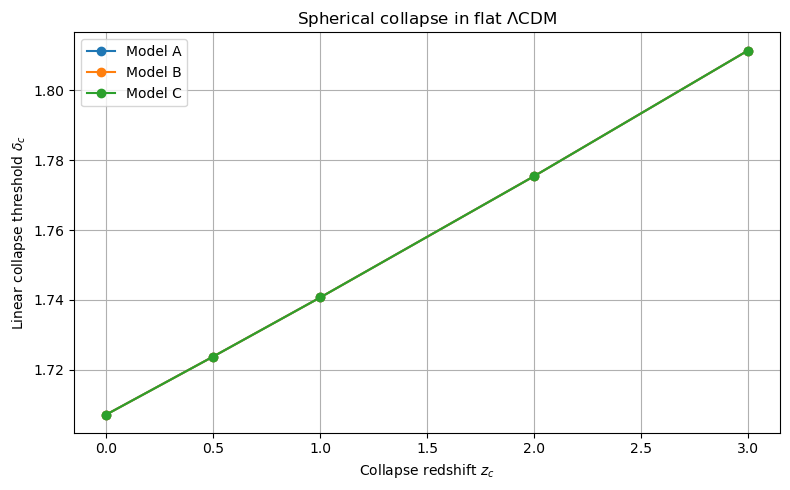

In [9]:
cosmology = FLRW(
    h=0.67,
    Omega_m=1.0,
    Omega_lambda=0.0,
    Omega_r=0.0,
    w0_fld=-1.0,
    wa_fld=0.0,
)

a_grid = np.geomspace(1e-6, 1.0, 2000)
N_grid = np.log(a_grid)

growth_sol = cosmology.solve_growth(
    N=N_grid,
    y0=[1e-6, 1e-6],
    rtol=1e-10,
    atol=1e-12,
)

if not growth_sol.success:
    raise RuntimeError(growth_sol.message)

def growth_rate(cosmology, growth_sol, ai):
    """
    Calculate f = dln(D)/dln(a) at ai.
    """
    _, f_i = cosmology.get_growth_observables(
        growth_sol,
        N_eval=np.array([np.log(ai)]),
    )

    return float(f_i[0])

models = ["A", "B", "C"]
redshifts = [0, 0.5, 1, 2, 3]

ai = 0.01
delta_stop = 1e4

collapse = SphericalCollapse(
    cosmology=cosmology,
)

results = []

for model in models:
    for z_c in redshifts:

        f_i = growth_rate(cosmology, growth_sol, ai)

        threshold = CollapseThreshold(
            collapse=collapse,
            model=model,
            ai=ai,
            delta_stop=delta_stop,
            f_i=f_i,
            n_points=1000,
            delta_i_min=1e-8,
            delta_i_max=1e-2,
            tol=1e-10,
            max_iter=100,
        )

        delta_i, delta_c = threshold.find(z_c)

        results.append({
            "Model": model,
            "z_c": z_c,
            "a_c": 1.0 / (1.0 + z_c),
            "f_i": f_i,
            "delta_i": delta_i,
            "delta_c": delta_c,
        })

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

pivot = results_df.pivot(
    index="z_c",
    columns="Model",
    values="delta_c",
)

print("Linear collapse thresholds:")
print(pivot)

relative_difference = 100.0 * pivot.div(
    pivot["A"],
    axis=0,
).subtract(1.0)

print("\nRelative difference with respect to Model A (%):")
print(relative_difference)

plt.figure(figsize=(8, 5))

for model in models:
    subset = results_df[results_df["Model"] == model]

    plt.plot(
        subset["z_c"],
        subset["delta_c"],
        marker="o",
        label=f"Model {model}",
    )

plt.xlabel(r"Collapse redshift $z_c$")
plt.ylabel(r"Linear collapse threshold $\delta_c$")
plt.title(r"Spherical collapse in flat $\Lambda$CDM")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()